In [34]:
#bash
#!pip install -q flwr[simulation] flwr_datasets[vision] torch torchvision matplotlib tensorflow scikit-learn 

#zsh
#!pip install -q flwr\[simulation\] flwr_datasets\[vision\] torch torchvision matplotlib tensorflow scikit-learn 

In [35]:
import time

from collections import OrderedDict
from typing import List, Tuple

import matplotlib.pyplot as plt
import seaborn as sns

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, Dataset
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import balanced_accuracy_score, f1_score, precision_score, confusion_matrix

import flwr
from flwr.client import Client, NumPyClient
from flwr.server import ServerConfig
from flwr.common import Metrics
from flwr.server.strategy import FedAvg
from flwr.simulation import start_simulation

DEVICE = torch.device("cpu")  # Try "cuda" to train on GPU
print(f"Training on {DEVICE}")
print(f"Flower {flwr.__version__} / PyTorch {torch.__version__}")

Training on cpu
Flower 1.10.0 / PyTorch 2.2.2


In [36]:
# Define the path to the dataset and the sequence length
PATH = '../datasets/pamap_balanced.csv'
NUM_CLIENTS_TRAIN = 2
NUM_CLIENTS_TEST = 1
NUM_CLASSES = 6
NUM_FEATURES = 12
NUM_ROUNDS = 1
NUM_EPOCHS = 3
SEQUENCE_LENGTH = 200
STRIDE = 100
BATCH_SIZE = 64

FEATURE_COLUMNS = ['hand_acc_16g_x', 'hand_acc_16g_y', 'hand_acc_16g_z',
        'hand_acc_6g_x', 'hand_acc_6g_y', 'hand_acc_6g_z',	
        'hand_gyro_x', 'hand_gyro_y', 'hand_gyro_z',	
        'hand_mag_x', 'hand_mag_y', 'hand_mag_z']

USER_COLUMN = 'subject_id'

ACTIVITY_COLUMN = 'activity_id'

BACKEND_CONFIG = {"client_resources": {"num_cpus": 1, "num_gpus": 0.0}}
if DEVICE.type == "cuda":
    BACKEND_CONFIG = {"client_resources": {"num_cpus": 1, "num_gpus": 1.0}}



In [37]:
class PAMAPDataset(Dataset):
    def __init__(self, data, transform=None, sequence_length=50, stride=1):
        self.data = data
        self.transform = transform
        self.sequence_length = sequence_length
        self.stride = stride

    def __len__(self):
        return (len(self.data) - self.sequence_length) // self.stride + 1

    def __getitem__(self, idx):
        # Calculate the starting index based on stride
        start_idx = idx * self.stride
        end_idx = start_idx + self.sequence_length
        
        # Select a window of data points
        window = self.data.iloc[start_idx:end_idx]
        
        # Extract x, y, z values and convert to tensors
        x = torch.tensor(window[FEATURE_COLUMNS].values, dtype=torch.float32)
        
        # The label is the activity of the last element in the sequence
        y = torch.tensor(int(window.iloc[-1][ACTIVITY_COLUMN]), dtype=torch.long)
        
        sample = {'data': x, 'label': y}
        
        if self.transform:
            sample = self.transform(sample)
        
        return sample


In [38]:
# Load data from file
df = pd.read_csv(PATH)

# Map activities to integers if not already done
activity_mapping = {activity: idx for idx, activity in enumerate(df[ACTIVITY_COLUMN].unique())}
df[ACTIVITY_COLUMN] = df[ACTIVITY_COLUMN].map(activity_mapping)

# Split the dataset by user_id
user_ids = df[USER_COLUMN].unique()
user_ids

array([1, 2, 3, 4, 5, 6, 7, 8])

In [39]:
def manual_stratified_split(df, stratify_column, test_size=0.2):
    """
    Manually split the DataFrame into training and validation sets while preserving class distribution.

    Parameters:
    - df: DataFrame containing the data
    - test_size: proportion of the dataset to include in the validation set

    Returns:
    - train_df: DataFrame for training
    - val_df: DataFrame for validation
    """
    try:
        # Get the unique classes
        classes = df[stratify_column].unique()
        
        # Initialize DataFrames for train and validation
        train_df = pd.DataFrame()
        val_df = pd.DataFrame()
        
        for cls in classes:
            class_df = df[df[stratify_column] == cls]
            train_class_df, val_class_df = train_test_split(
                class_df,
                test_size=test_size,
                shuffle=False
            )
            train_df = pd.concat([train_df, train_class_df])
            val_df = pd.concat([val_df, val_class_df])
        
        return train_df, val_df
    except Exception as e:
        print(f"An error occurred (manual_stratified_split): {e}")
        return None, None

In [40]:
def load_client_data(partition_id: int):
    try:
        if not isinstance(partition_id, int): # Force conversion to int
            partition_id = int(partition_id)

        # Select the data for this partition
        partition_df = df[df[USER_COLUMN] == partition_id].copy()
        scaler = StandardScaler()
        partition_df[FEATURE_COLUMNS] = scaler.fit_transform(partition_df[FEATURE_COLUMNS])

       # Split the data into train and validation (80% train, 20% validation)
        train_df, val_df = manual_stratified_split(partition_df, ACTIVITY_COLUMN, test_size=0.2)
        
        # Create Dataset objects
        train_dataset = PAMAPDataset(train_df, transform=None, sequence_length=SEQUENCE_LENGTH, stride=STRIDE)
        val_dataset = PAMAPDataset(val_df, transform=None, sequence_length=SEQUENCE_LENGTH, stride=STRIDE)

        # Create DataLoader objects
        trainloader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
        valloader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False)
        
        return trainloader, valloader
    except Exception as e:
        print(f"An error occurred (load_client_data): {e}")
        return None, None

In [41]:
trainloader, valloader = load_client_data(partition_id=1)
batch = next(iter(trainloader))
data, labels = batch["data"], batch["label"]
x_shape = data.shape
y_shape = labels.shape
x_shape, y_shape

(torch.Size([64, 200, 12]), torch.Size([64]))

In [42]:
def load_test_data():
    try:
        test_clients = user_ids[-NUM_CLIENTS_TEST:]
        print(test_clients)
        combined_df = pd.DataFrame()

        for client_id in test_clients:
        # Select the data for this partition
            partition_df = df[df[USER_COLUMN] == client_id].copy()
            scaler = StandardScaler()
            partition_df[FEATURE_COLUMNS] = scaler.fit_transform(partition_df[FEATURE_COLUMNS])
            combined_df = pd.concat([combined_df, partition_df])

        # Reset the index of the combined DataFrame
        combined_df.reset_index(drop=True, inplace=True)

        # Create Dataset objects
        testdataset = PAMAPDataset(partition_df, transform=None, sequence_length=SEQUENCE_LENGTH, stride=STRIDE)

        # Create DataLoader objects
        testloader = DataLoader(testdataset, batch_size=BATCH_SIZE, shuffle=True)
        
        return testloader
    except Exception as e:
        print(f"An error occurred (load_test_dataset): {e}")
        return None

In [43]:
testloader = load_test_data()
batch = next(iter(trainloader))
data, labels = batch["data"], batch["label"]
x_shape = data.shape
y_shape = labels.shape
x_shape, y_shape

[8]


(torch.Size([64, 200, 12]), torch.Size([64]))

In [44]:
class PEN(nn.Module):
    def __init__(self):
        super(PEN, self).__init__()
        # Convolutional layers
        self.conv1 = nn.Conv1d(in_channels=NUM_FEATURES, out_channels=128, kernel_size=11)
        self.bn1 = nn.BatchNorm1d(128)
        self.leaky_relu = nn.LeakyReLU()
        self.pool = nn.MaxPool1d(kernel_size=2, stride=2)

        self.conv2 = nn.Conv1d(in_channels=128, out_channels=128, kernel_size=7)
        self.bn2 = nn.BatchNorm1d(128)

        self.conv3 = nn.Conv1d(in_channels=128, out_channels=128, kernel_size=5)
        self.bn3 = nn.BatchNorm1d(128)
        
        # LSTM layers
        self.lstm1 = nn.LSTM(input_size=NUM_FEATURES, hidden_size=128, batch_first=True)
        self.lstm2 = nn.LSTM(input_size=128, hidden_size=128, batch_first=True)
        
        # Fully connected layer
        self.fc = nn.Linear(128 + 128, NUM_CLASSES)

    def attention_net(self, lstm_output):
        # LSTM output: [batch_size, seq_len, hidden_size]
        attention_weights = torch.bmm(lstm_output, lstm_output.transpose(1, 2))
        attention_weights = nn.functional.softmax(attention_weights, dim=-1)

        # Multiply attention weights with the LSTM output
        attended_output = torch.bmm(attention_weights, lstm_output)
        return attended_output.mean(dim=1)  # Reduce dimension to [batch_size, hidden_size]

    def forward(self, x):
        # Convolutional path
        x_cnn = self.conv1(x)
        x_cnn = self.bn1(x_cnn)
        x_cnn = self.leaky_relu(x_cnn)
        x_cnn = self.pool(x_cnn)

        x_cnn = self.conv2(x_cnn)
        x_cnn = self.bn2(x_cnn)
        x_cnn = self.leaky_relu(x_cnn)
        x_cnn = self.pool(x_cnn)

        x_cnn = self.conv3(x_cnn)
        x_cnn = self.bn3(x_cnn)
        x_cnn = self.leaky_relu(x_cnn)
        x_cnn = self.pool(x_cnn)
        
        x_cnn = x_cnn.mean(dim=-1)  # Global Average Pooling

        # LSTM path
        x_lstm, _ = self.lstm1(x.transpose(1, 2))  # Transpose to match LSTM input shape
        x_lstm, _ = self.lstm2(x_lstm)  # Pass through the second LSTM layer

        # Apply attention
        x_lstm = self.attention_net(x_lstm)

        # Concatenate CNN and LSTM paths
        x = torch.cat((x_cnn, x_lstm), dim=1)

        # Fully connected layer
        x = self.fc(x)
        return x

In [45]:
def train(net, trainloader, epochs: int, verbose=False):
    """Train the PEN network on the training set."""
    try:
        criterion = torch.nn.CrossEntropyLoss()
        optimizer = torch.optim.Adam(net.parameters())
        net.train()

        for epoch in range(epochs):
            correct, total, epoch_loss = 0, 0, 0.0
            start_epoch_time = time.time()
            for batch in trainloader:
                data, labels = batch["data"].to(DEVICE), batch["label"].to(DEVICE)
                data = data.transpose(2, 1)

                optimizer.zero_grad()
                outputs = net(data)
                loss = criterion(outputs, labels)
                loss.backward()
                optimizer.step()
                
                epoch_loss += loss.item()
                total += labels.size(0)
                correct += (torch.max(outputs.data, 1)[1] == labels).sum().item()

            avg_loss = epoch_loss / len(trainloader)
            end_epoch_time = time.time()
            epoch_time = end_epoch_time - start_epoch_time

            if(verbose):
                print(f'Epoch [{epoch+1}/{epochs}], Loss: {avg_loss:.4f}, Time: {epoch_time:.2f} seconds')
                
    except Exception as e:
        print(f"An error occurred (train): {e}")

In [46]:
def test(net, testloader):
    """Evaluate the PEN network on the entire test set and return various metrics."""
    try:
        criterion = torch.nn.CrossEntropyLoss()
        correct, total, loss = 0, 0, 0.0
        net.eval()
        
        all_labels = []
        all_predictions = []

        with torch.no_grad():
            for batch in testloader:
                data, labels = batch["data"].to(DEVICE), batch["label"].to(DEVICE)
                data = data.transpose(2, 1)
                outputs = net(data)

                loss += criterion(outputs, labels).item()
                _, predicted = torch.max(outputs.data, 1)

                total += labels.size(0)
                correct += (predicted == labels).sum().item()
                all_labels.extend(labels.cpu().numpy())
                all_predictions.extend(predicted.cpu().numpy())

        # Calculate metrics
        loss /= len(testloader.dataset)
        balanced_acc = balanced_accuracy_score(all_labels, all_predictions)
        f1 = f1_score(all_labels, all_predictions, average='weighted')
        precision = precision_score(all_labels, all_predictions, average='weighted')
        conf_matrix = confusion_matrix(all_labels, all_predictions, normalize='true').round(2)

        return loss, balanced_acc, f1, precision, conf_matrix

    except Exception as e:
        print(f"An error occurred (test): {e}")
        return None, None, None, None, None


In [47]:
net = PEN().to(DEVICE)
trainloader, valloader = load_client_data(partition_id=1)  # Load client-specific data

In [48]:
train(net, trainloader, NUM_EPOCHS, verbose=True)

Epoch [1/3], Loss: 0.9334, Time: 13.44 seconds
Epoch [2/3], Loss: 0.4710, Time: 12.79 seconds
Epoch [3/3], Loss: 0.3250, Time: 12.89 seconds


In [49]:
_, balanced_acc, precision, f1, conf_matrix = test(net, valloader)
print(f"  Balanced Accuracy: {balanced_acc:.4f}")
print(f"  Precision: {precision:.4f}")
print(f"  F1 Score: {f1:.4f}")
print(f"  Confusion Matrix: \n{conf_matrix.round(2)}")

  Balanced Accuracy: 0.7350
  Precision: 0.7169
  F1 Score: 0.7226
  Confusion Matrix: 
[[0.64 0.31 0.04 0.   0.   0.  ]
 [0.11 0.36 0.16 0.02 0.07 0.27]
 [0.03 0.03 0.88 0.   0.06 0.  ]
 [0.03 0.07 0.07 0.83 0.   0.  ]
 [0.05 0.09 0.05 0.   0.82 0.  ]
 [0.   0.07 0.02 0.   0.02 0.88]]


# Federated Model

### Client

In [50]:
def set_parameters(net, parameters: List[np.ndarray]):
    try:
        params_dict = zip(net.state_dict().keys(), parameters)
        state_dict = OrderedDict({k: torch.from_numpy(np.copy(v)) for k, v in params_dict})
        net.load_state_dict(state_dict, strict=True)
    except Exception as e:
        print(f"An error occurred (set_parameters): {e}")


def get_parameters(net) -> List[np.ndarray]:
    try:
        return [val.cpu().numpy() for _, val in net.state_dict().items()]
    except Exception as e:
        print(f"An error occurred (get_parameters): {e}")
        return None

In [51]:
class FlowerClient(NumPyClient):
    def __init__(self, net, trainloader, valloader):
        self.net = net
        self.trainloader = trainloader
        self.valloader = valloader

    def get_parameters(self, config):
        return get_parameters(self.net)

    def fit(self, parameters, config):
        set_parameters(self.net, parameters)
        train(self.net, self.trainloader, epochs=NUM_EPOCHS)
        return get_parameters(self.net), len(self.trainloader), {}

    def evaluate(self, parameters, config):
        set_parameters(self.net, parameters)
        loss, balanced_acc, f1, precision, conf_matrix = test(self.net, self.valloader)
        return float(loss), len(self.valloader), {"accuracy": float(balanced_acc), "f1score": float(f1), "precision": float(precision)}

In [60]:
def client_fn(context) -> Client:
    """Create a Flower client representing a single organization."""
    try:
        # Load model
        net = PEN().to(DEVICE)

        partition_id = context.node_config["partition-id"]
        #partition_id = str(context)
        client_id = int(partition_id) + 1
        trainloader, valloader = load_client_data(partition_id=client_id)

        return FlowerClient(net, trainloader, valloader).to_client()
    except Exception as e:
        print(f"An error occurred (client_fn): {e}")
        return None

### Server

In [61]:
def weighted_average(metrics: List[Tuple[int, Metrics]]) -> Metrics:
    try:
        # Multiply accuracy of each client by number of examples used
        accuracies = [num_examples * m["accuracy"] for num_examples, m in metrics]
        f1s = [num_examples * m["f1score"] for num_examples, m in metrics]
        precisions = [num_examples * m["precision"] for num_examples, m in metrics]
        examples = [num_examples for num_examples, _ in metrics]

        # Aggregate and return custom metric (weighted average)
        return {"accuracy": sum(accuracies) / sum(examples), "f1score": sum(f1s) / sum(examples), "precision": sum(precisions) / sum(examples)}
    except Exception as e:
        print(f"An error occurred (weighted_average): {e}")
        return None

In [62]:
def server_evaluate_fn(server_round:int, parameters, config):
    try:
        model = PEN().to(DEVICE)

        params_dict = zip(net.state_dict().keys(), parameters)
        state_dict = OrderedDict({k: torch.from_numpy(np.copy(v)) for k, v in params_dict})
        model.load_state_dict(state_dict, strict=True)

        loss, balanced_acc, f1, precision, conf_matrix = test(model, testloader)

        return float(loss), {"accuracy": float(balanced_acc), "f1score": float(f1), "precision": float(precision)}
    except Exception as e:
        print(f"An error occurred (server_evaluate_fn): {e}")
        return None, None


### Simulation

In [63]:
# Create FedAvg strategy
strategy = FedAvg(
    fraction_fit=1.0,  # Sample % of available clients for training
    fraction_evaluate=0.5,  # Sample % of available clients for evaluation
    min_fit_clients=NUM_CLIENTS_TRAIN,  # sample  clients for training
    min_evaluate_clients=NUM_CLIENTS_TRAIN,  # sample clients for evaluation
    min_available_clients=NUM_CLIENTS_TRAIN,  # Wait until all clients are available
    evaluate_metrics_aggregation_fn=weighted_average,
    evaluate_fn=server_evaluate_fn,
)

# Configure the server for 5 rounds of training
config = ServerConfig(num_rounds=NUM_ROUNDS)


hist = start_simulation(
    num_clients=NUM_CLIENTS_TRAIN,
    client_fn=client_fn,
    strategy=strategy,
    config=config,
)

INFO :      Starting Flower simulation, config: num_rounds=1, no round_timeout


2024-09-01 13:36:42,319	INFO worker.py:1752 -- Started a local Ray instance.
INFO :      Flower VCE: Ray initialized with resources: {'memory': 2887908558.0, 'node:127.0.0.1': 1.0, 'CPU': 4.0, 'node:__internal_head__': 1.0, 'object_store_memory': 1443954278.0}
INFO :      Optimize your simulation with Flower VCE: https://flower.ai/docs/framework/how-to-run-simulations.html
INFO :      No `client_resources` specified. Using minimal resources for clients.
INFO :      Flower VCE: Resources for each Virtual Client: {'num_cpus': 1, 'num_gpus': 0.0}
INFO :      Flower VCE: Creating VirtualClientEngineActorPool with 4 actors
INFO :      [INIT]
INFO :      Requesting initial parameters from one random client
(pid=1849) 2024-09-01 13:36:53.551635: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
(pid=1849) To enable the following instructions: AVX2 FMA, in other operations, rebuild Tens

In [66]:
def plot_metrics_by_round(data, legend, is_loss=False):
    df = pd.DataFrame(data, columns=["Round", "Accuracy"])
    # Set the style
    # Set the style
    sns.set_theme(style="dark")

    # Create the line plot with customizations
    plt.figure(figsize=(10, 6))
    sns.lineplot(x="Round", y="Accuracy", data=df, marker="o", color="royalblue", linewidth=2.5)

    # Customize the title and labels
    plt.title(f"{legend} per Round", fontsize=16, fontweight='bold')
    plt.xlabel("Round", fontsize=14)
    plt.ylabel(legend, fontsize=14)

    # Customize the grid
    plt.grid(True, which='both', linestyle='--', linewidth=0.5)

    # Customize the ticks
    plt.xticks(ticks=df["Round"], fontsize=12)  # Ensure only integer rounds are shown on x-axis
    plt.yticks(fontsize=12)

    # Add a range for the y-axis for better visibility
    if(not is_loss):
        plt.ylim(0, 1)

    # Display the plot
    plt.show()

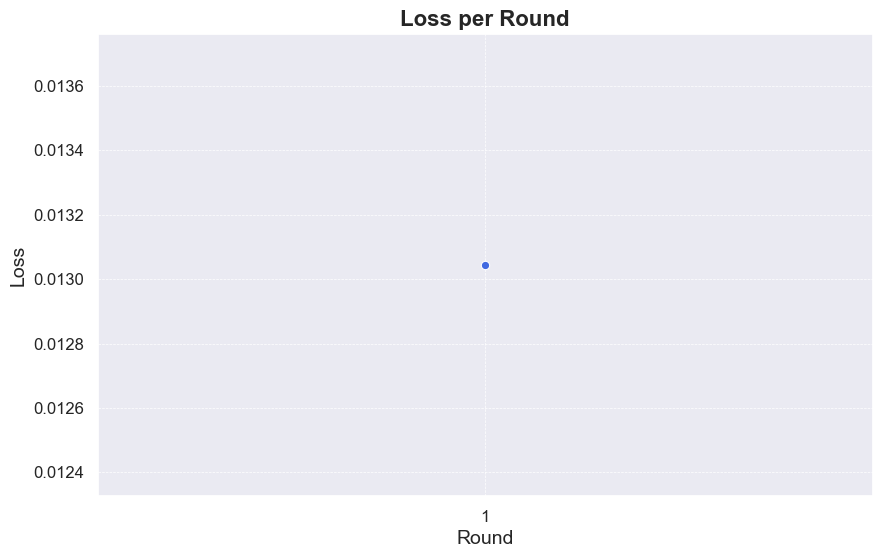

In [67]:
plot_metrics_by_round(hist.losses_distributed, 'Loss', True)

In [68]:
def plot_multiple_metrics_by_round(data1, data2, data3, legend):
    # Convert data to DataFrames
    df1 = pd.DataFrame(data1, columns=["Round", "Metric"])
    df2 = pd.DataFrame(data2, columns=["Round", "Metric"])
    df3 = pd.DataFrame(data3, columns=["Round", "Metric"])
    
    # Set the style
    sns.set_theme(style="dark")
    
    # Create the main plot
    plt.figure(figsize=(10, 6))
    
    # Plot each metric with different styles
    sns.lineplot(x="Round", y="Metric", data=df1, marker="o", color="royalblue", linewidth=2.5, label="Accuracy")
    sns.lineplot(x="Round", y="Metric", data=df2, marker="s", color="forestgreen", linewidth=2.5, label="F1 Score")
    sns.lineplot(x="Round", y="Metric", data=df3, marker="^", color="darkorange", linewidth=2.5, label="Precision")
    
    # Customize the title and labels
    plt.title(f"{legend} Metrics per Round", fontsize=16, fontweight='bold')
    plt.xlabel("Round", fontsize=14)
    plt.ylabel("Value", fontsize=14)
    
    # Customize the grid
    plt.grid(True, which='both', linestyle='--', linewidth=0.5)
    
    # Calculate and set x-axis ticks
    round_ticks = range(0, max(df1["Round"].max(), df2["Round"].max(), df3["Round"].max()) + 10, 10)
    plt.xticks(ticks=round_ticks, fontsize=12)  # Ensure only integer rounds are shown on x-axis
    
    # Customize the y-axis ticks
    plt.yticks(fontsize=12)
    
    # Set y-axis limits
    plt.ylim(0.2, 1.0)
    
    # Add a legend
    plt.legend(title="Metrics", title_fontsize='13', fontsize='12')
    
    # Inset plot for the last 5 values
    inset_axes = plt.gca().inset_axes([0.6, 0.1, 0.35, 0.35])  # Position inset: [left, bottom, width, height]
    sns.lineplot(x="Round", y="Metric", data=df1.tail(5), marker="o", color="royalblue", linewidth=2.0, ax=inset_axes)
    sns.lineplot(x="Round", y="Metric", data=df2.tail(5), marker="s", color="forestgreen", linewidth=2.0, ax=inset_axes)
    sns.lineplot(x="Round", y="Metric", data=df3.tail(5), marker="^", color="darkorange", linewidth=2.0, ax=inset_axes)
    
    # Annotate the last point in the inset
    for df, color in zip([df1, df2, df3], ["royalblue", "forestgreen", "darkorange"]):
        last_point = df.tail(5).iloc[-1]
        inset_axes.text(last_point["Round"], last_point["Metric"]*0.985, 
                        f"{last_point['Metric']:.2f}", 
                        fontsize=10, fontweight='bold', color=color,
                        ha='right', va='bottom')
    
    # Customize the inset plot
    inset_axes.set_xlim(df1["Round"].max() - 4, df1["Round"].max())  # Set x-axis range for last 5 rounds
    #inset_axes.set_ylim(0.2, 1.0)  # Match y-axis limits to the main plot
    inset_axes.set_title("Last 5 Rounds", fontsize=12)
    inset_axes.set_ylabel("Value")
    inset_axes.grid(True, which='both', linestyle='--', linewidth=0.5)
    
    # Display the plot
    plt.show()

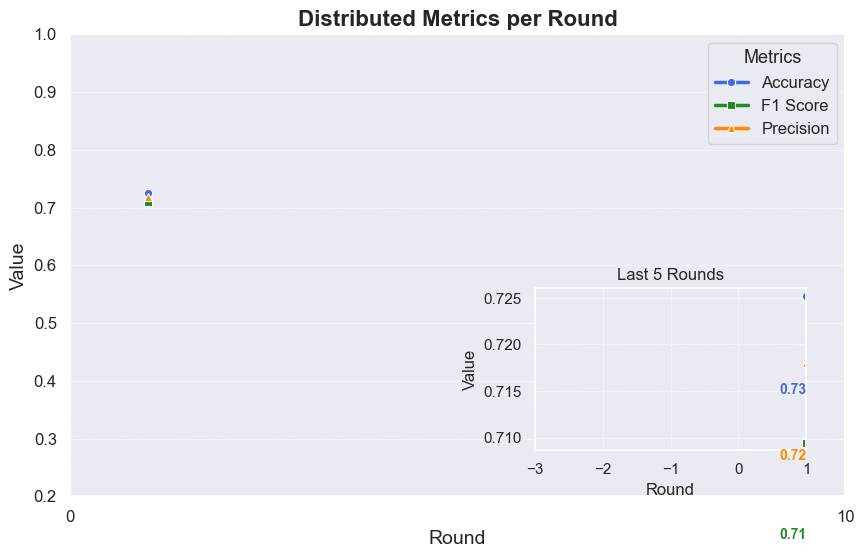

In [69]:
plot_multiple_metrics_by_round(hist.metrics_distributed['accuracy'], hist.metrics_distributed['f1score'], hist.metrics_distributed['precision'], 'Distributed')

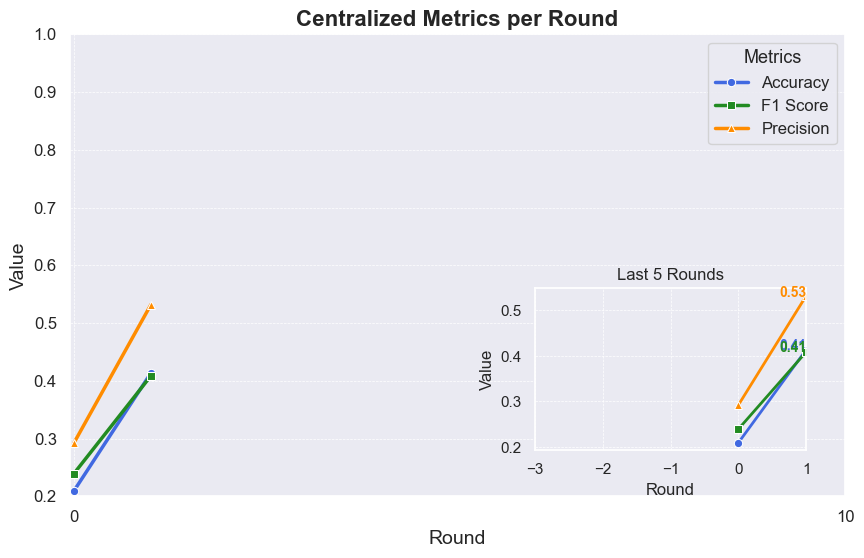

In [70]:
plot_multiple_metrics_by_round(hist.metrics_centralized['accuracy'], hist.metrics_centralized['f1score'], hist.metrics_centralized['precision'], 'Centralized')